# AetherAI — AI Cost & Token Analytics
## Google Colab Analysis Notebook

**Purpose:** Load the AetherAI CSV files, validate data quality, independently calculate usage/cost/business-value KPIs, analyse monthly and model performance, and export clean summary files.

**Important:** This notebook analyses the existing dataset. It does not regenerate or overwrite your original CSV files. The data is synthetic; pricing, budgets, labor rates and time saved are assumptions.

### How to use
1. Open this notebook in Google Colab.
2. Run cells from top to bottom.
3. When prompted, upload the seven AetherAI CSV files.
4. If your CSV column names differ, inspect the column list and adjust the mapping cell.
5. Review the validation outputs before trusting any KPI.


## 1. Import libraries

In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display
from pathlib import Path
import io
import zipfile
import os

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
print("Libraries loaded successfully.")

Libraries loaded successfully.


## 2. Upload your CSV files

Select the seven existing files:
- `departments.csv`
- `employees.csv`
- `ai_models.csv`
- `ai_requests.csv`
- `token_usage.csv`
- `task_outcomes.csv`
- `department_budgets.csv`

You can select multiple files together. If you have one ZIP containing the CSVs, upload the ZIP instead.

In [69]:
uploaded = files.upload()

data_dir = Path("/content/aetherai_data")
data_dir.mkdir(exist_ok=True)

for filename, content in uploaded.items():
    if filename.lower().endswith(".zip"):
        with zipfile.ZipFile(io.BytesIO(content)) as z:
            z.extractall(data_dir)
    else:
        (data_dir / filename).write_bytes(content)

print("Files available:")
for p in sorted(data_dir.rglob("*")):
    if p.is_file():
        print(p.relative_to(data_dir))

Files available:
ai_models.csv
ai_requests.csv
department_budgets.csv
departments.csv
employees.csv
task_outcomes.csv
token_usage.csv


## 3. Load the seven tables
If the filenames are different, edit the mapping below. The loader searches subfolders too.

In [70]:
def find_csv(filename):
    matches = list(data_dir.rglob(filename))
    if not matches:
        raise FileNotFoundError(
            f"Could not find {filename}. Check the uploaded filenames/folders."
        )
    return matches[0]

file_map = {
    "departments": "departments.csv",
    "employees": "employees.csv",
    "ai_models": "ai_models.csv",
    "ai_requests": "ai_requests.csv",
    "token_usage": "token_usage.csv",
    "task_outcomes": "task_outcomes.csv",
    "department_budgets": "department_budgets.csv",
}

tables = {name: pd.read_csv(find_csv(filename)) for name, filename in file_map.items()}

for name, df in tables.items():
    print(f"{name}: {df.shape[0]:,} rows × {df.shape[1]} columns")
    display(df.head(3))

departments: 5 rows × 3 columns


,department_id,department_name,monthly_budget_usd
0,1,Customer Support,1800
1,2,Engineering,3200
2,3,Marketing,1500


employees: 120 rows × 4 columns


,employee_id,employee_name,department_id,role
0,1001,Employee_001,4,Analyst
1,1002,Employee_002,2,Manager
2,1003,Employee_003,5,Analyst


ai_models: 3 rows × 6 columns


,model_id,provider,model_name,input_rate_per_million_usd,output_rate_per_million_usd,model_tier
0,1,Aether Cloud,Aether-Flash,0.2000,0.8000,Low Cost
1,2,Aether Cloud,Aether-Pro,2.0000,8.0000,Premium
2,3,Open Model Hub,OpenLite,0.1000,0.4000,Low Cost


... (4 outputs left out)

task_outcomes: 12,000 rows × 5 columns


,request_id,task_type,task_successful,time_saved_minutes,hourly_labor_cost_usd
0,500001,Customer Reply,True,13,32.0400
1,500002,Customer Reply,True,5,35.7000
2,500003,Code Assistance,True,16,46.3000


department_budgets: 60 rows × 3 columns


,department_id,budget_month,budget_amount_usd
0,1,2025-01-01,1800
1,1,2025-02-01,1800
2,1,2025-03-01,1800


## 4. Inspect columns and data types

In [71]:
for name, df in tables.items():
    print("\n" + "="*80)
    print(name)
    print("Columns:", df.columns.tolist())
    display(df.dtypes.rename("data_type").to_frame())


departments
Columns: ['department_id', 'department_name', 'monthly_budget_usd']


,data_type
department_id,int64
department_name,object
monthly_budget_usd,int64



employees
Columns: ['employee_id', 'employee_name', 'department_id', 'role']


,data_type
employee_id,int64
employee_name,object
department_id,int64
role,object



ai_models
Columns: ['model_id', 'provider', 'model_name', 'input_rate_per_million_usd', 'output_rate_per_million_usd', 'model_tier']


,data_type
model_id,int64
provider,object
model_name,object
input_rate_per_million_usd,float64
output_rate_per_million_usd,float64
model_tier,object


... (4 outputs left out)


task_outcomes
Columns: ['request_id', 'task_type', 'task_successful', 'time_saved_minutes', 'hourly_labor_cost_usd']


,data_type
request_id,int64
task_type,object
task_successful,bool
time_saved_minutes,int64
hourly_labor_cost_usd,float64



department_budgets
Columns: ['department_id', 'budget_month', 'budget_amount_usd']


,data_type
department_id,int64
budget_month,object
budget_amount_usd,int64


## 5. Standardise key data types
This cell converts timestamps, numeric fields and common Boolean representations. Review the printed results.

In [72]:
# Parse request timestamp
tables["ai_requests"]["request_time"] = pd.to_datetime(
    tables["ai_requests"]["request_time"], errors="coerce"
)

numeric_columns = {
    "token_usage": ["input_tokens", "output_tokens"],
    "ai_requests": ["latency_ms"],
    "ai_models": ["input_rate_per_million_usd", "output_rate_per_million_usd"],
    "task_outcomes": ["time_saved_minutes", "hourly_labor_cost_usd"],
    "department_budgets": ["budget_amount_usd"],
}

for table_name, cols in numeric_columns.items():
    for col in cols:
        if col in tables[table_name].columns:
            tables[table_name][col] = pd.to_numeric(
                tables[table_name][col], errors="coerce"
            )

for name, df in tables.items():
    print(name, "loaded; rows =", len(df))

departments loaded; rows = 5
employees loaded; rows = 120
ai_models loaded; rows = 3
ai_requests loaded; rows = 12000
token_usage loaded; rows = 12000
task_outcomes loaded; rows = 12000
department_budgets loaded; rows = 60


## 6. Data quality overview

In [73]:
quality_rows = []
for name, df in tables.items():
    quality_rows.append({
        "table": name,
        "rows": len(df),
        "columns": len(df.columns),
        "missing_cells": int(df.isna().sum().sum()),
        "duplicate_full_rows": int(df.duplicated().sum())
    })

quality_summary = pd.DataFrame(quality_rows)
display(quality_summary)

print("Request date range:")
display(tables["ai_requests"]["request_time"].agg(["min", "max"]).to_frame("request_time"))

,table,rows,columns,missing_cells,duplicate_full_rows
0,departments,5,3,0,0
1,employees,120,4,0,0
2,ai_models,3,6,0,0
3,ai_requests,12000,7,0,0
4,token_usage,12000,3,0,0
5,task_outcomes,12000,5,0,0
6,department_budgets,60,3,0,0


Request date range:


,request_time
min,2025-01-01 00:12:11
max,2025-12-31 23:27:38


## 7. Primary-key and duplicate checks

In [74]:
key_candidates = {
    "departments": "department_id",
    "employees": "employee_id",
    "ai_models": "model_id",
    "ai_requests": "request_id",
    "token_usage": "request_id",
    "task_outcomes": "request_id",
}

key_results = []
for table_name, key in key_candidates.items():
    df = tables[table_name]
    if key in df.columns:
        key_results.append({
            "table": table_name,
            "key": key,
            "null_key_rows": int(df[key].isna().sum()),
            "duplicate_key_rows": int(df[key].duplicated().sum())
        })
    else:
        key_results.append({
            "table": table_name, "key": key,
            "null_key_rows": None, "duplicate_key_rows": None
        })

display(pd.DataFrame(key_results))

,table,key,null_key_rows,duplicate_key_rows
0,departments,department_id,0,0
1,employees,employee_id,0,0
2,ai_models,model_id,0,0
3,ai_requests,request_id,0,0
4,token_usage,request_id,0,0
5,task_outcomes,request_id,0,0


## 8. Check invalid token counts, latency, pricing and outcomes

In [75]:
checks = {}

tu = tables["token_usage"]
checks["negative_input_tokens"] = int((tu["input_tokens"] < 0).sum()) if "input_tokens" in tu else None
checks["negative_output_tokens"] = int((tu["output_tokens"] < 0).sum()) if "output_tokens" in tu else None

ar = tables["ai_requests"]
checks["negative_latency"] = int((ar["latency_ms"] < 0).sum()) if "latency_ms" in ar else None
checks["missing_request_time"] = int(ar["request_time"].isna().sum()) if "request_time" in ar else None

models = tables["ai_models"]
for col in ["input_rate_per_million_usd", "output_rate_per_million_usd"]:
    checks[f"negative_{col}"] = int((models[col] < 0).sum()) if col in models else None

outcomes = tables["task_outcomes"]
for col in ["time_saved_minutes", "hourly_labor_cost_usd"]:
    checks[f"negative_{col}"] = int((outcomes[col] < 0).sum()) if col in outcomes else None

display(pd.Series(checks, name="issue_count").to_frame())

,issue_count
negative_input_tokens,0
negative_output_tokens,0
negative_latency,0
missing_request_time,0
negative_input_rate_per_million_usd,0
negative_output_rate_per_million_usd,0
negative_time_saved_minutes,0
negative_hourly_labor_cost_usd,0


## 9. Join data and calculate request-level cost

The calculation is:

`((input_tokens × input_rate) + (output_tokens × output_rate)) / 1,000,000`

This cell uses explicit joins and checks for duplicate request/model keys to reduce accidental row multiplication. If the join expands the request/token row count unexpectedly, stop and inspect the key uniqueness results.

In [76]:
requests = tables["ai_requests"].copy()
tokens = tables["token_usage"].copy()
models = tables["ai_models"].copy()

required = {
    "requests": {"request_id", "model_id", "request_time", "request_status"},
    "tokens": {"request_id", "input_tokens", "output_tokens"},
    "models": {"model_id", "input_rate_per_million_usd", "output_rate_per_million_usd"}
}
for label, cols in required.items():
    frame = {"requests": requests, "tokens": tokens, "models": models}[label]
    missing = cols - set(frame.columns)
    if missing:
        raise ValueError(f"{label} is missing required columns: {sorted(missing)}")

if models["model_id"].duplicated().any():
    raise ValueError("ai_models.model_id is not unique. Resolve duplicates before calculating cost.")
if tokens["request_id"].duplicated().any():
    raise ValueError("token_usage.request_id is not unique. Resolve duplicates before calculating cost.")

request_cost = (
    requests.merge(tokens, on="request_id", how="left", validate="one_to_one")
            .merge(
                models[["model_id", "provider", "model_name", "model_tier",
                        "input_rate_per_million_usd", "output_rate_per_million_usd"]],
                on="model_id", how="left", validate="many_to_one"
            )
)

request_cost["input_cost_usd"] = (
    request_cost["input_tokens"] *
    request_cost["input_rate_per_million_usd"] / 1_000_000
)
request_cost["output_cost_usd"] = (
    request_cost["output_tokens"] *
    request_cost["output_rate_per_million_usd"] / 1_000_000
)
request_cost["ai_cost_usd"] = (
    request_cost["input_cost_usd"] + request_cost["output_cost_usd"]
)

print("Requests:", len(requests), "| Request-cost rows:", len(request_cost))
print("Rows with missing token values:", int(request_cost[["input_tokens", "output_tokens"]].isna().any(axis=1).sum()))
print("Rows with missing model rates:", int(request_cost[["input_rate_per_million_usd", "output_rate_per_million_usd"]].isna().any(axis=1).sum()))
display(request_cost.head())

Requests: 12000 | Request-cost rows: 12000
Rows with missing token values: 0
Rows with missing model rates: 0


,request_id,employee_id,model_id,request_time,task_type,request_status,latency_ms,input_tokens,output_tokens,provider,model_name,model_tier,input_rate_per_million_usd,output_rate_per_million_usd,input_cost_usd,output_cost_usd,ai_cost_usd
0,500001,1028,1,2025-11-05 00:32:36,Customer Reply,Success,1745,1239,727,Aether Cloud,Aether-Flash,Low Cost,0.2000,0.8000,0.0002,0.0006,0.0008
1,500002,1037,1,2025-11-22 00:52:51,Customer Reply,Success,429,1321,611,Aether Cloud,Aether-Flash,Low Cost,0.2000,0.8000,0.0003,0.0005,0.0008
2,500003,1013,1,2025-03-23 23:22:04,Code Assistance,Success,2019,1261,608,Aether Cloud,Aether-Flash,Low Cost,0.2000,0.8000,0.0003,0.0005,0.0007
3,500004,1098,2,2025-11-23 12:40:03,Data Extraction,Success,1250,771,578,Aether Cloud,Aether-Pro,Premium,2.0000,8.0000,0.0015,0.0046,0.0062
4,500005,1079,2,2025-02-12 09:18:11,Customer Reply,Success,2217,536,969,Aether Cloud,Aether-Pro,Premium,2.0000,8.0000,0.0011,0.0078,0.0088


## 10. Core usage and cost KPIs

In [77]:
total_requests = requests["request_id"].nunique()
total_input_tokens = tokens["input_tokens"].sum()
total_output_tokens = tokens["output_tokens"].sum()
total_tokens = total_input_tokens + total_output_tokens

status = requests["request_status"].astype(str).str.strip().str.lower()
successful_requests = int((status == "success").sum())
request_success_rate = successful_requests / total_requests if total_requests else np.nan

# min_count=1 prevents an all-missing cost column from being silently treated as zero.
total_ai_cost = request_cost["ai_cost_usd"].sum(min_count=1)

core_kpis = pd.DataFrame({
    "Metric": [
        "Total Requests", "Successful Requests", "Request Success Rate",
        "Total Input Tokens", "Total Output Tokens", "Total Tokens",
        "Total AI Cost USD", "Average Latency ms"
    ],
    "Value": [
        total_requests, successful_requests, request_success_rate,
        total_input_tokens, total_output_tokens, total_tokens,
        total_ai_cost, requests["latency_ms"].mean()
    ]
})
display(core_kpis)

,Metric,Value
0,Total Requests,"12,000.0000"
1,Successful Requests,"11,476.0000"
2,Request Success Rate,0.9563
3,Total Input Tokens,"21,235,456.0000"
4,Total Output Tokens,"9,215,398.0000"
5,Total Tokens,"30,450,854.0000"
6,Total AI Cost USD,37.9021
7,Average Latency ms,"1,553.9827"


## 11. Monthly cost and requests

,year_month,requests,input_tokens,output_tokens,ai_cost_usd,total_tokens,cost_mom_change_pct
0,2025-01,999,1720054,812268,3.5649,2532322,NaN
1,2025-02,964,1731151,745917,2.8312,2477068,-20.5806
2,2025-03,1022,1754362,801955,3.2319,2556317,14.1514
3,2025-04,1026,1836643,772825,3.3343,2609468,3.1695
4,2025-05,978,1728151,763706,3.0868,2491857,-7.4215
5,2025-06,1007,1810172,763923,3.0190,2574095,-2.1989
6,2025-07,1056,1827183,815256,3.2120,2642439,6.3956
7,2025-08,1021,1757002,762102,3.1562,2519104,-1.7372
8,2025-09,958,1729391,741924,3.0455,2471315,-3.5093
9,2025-10,1008,1804313,766887,3.1800,2571200,4.4154


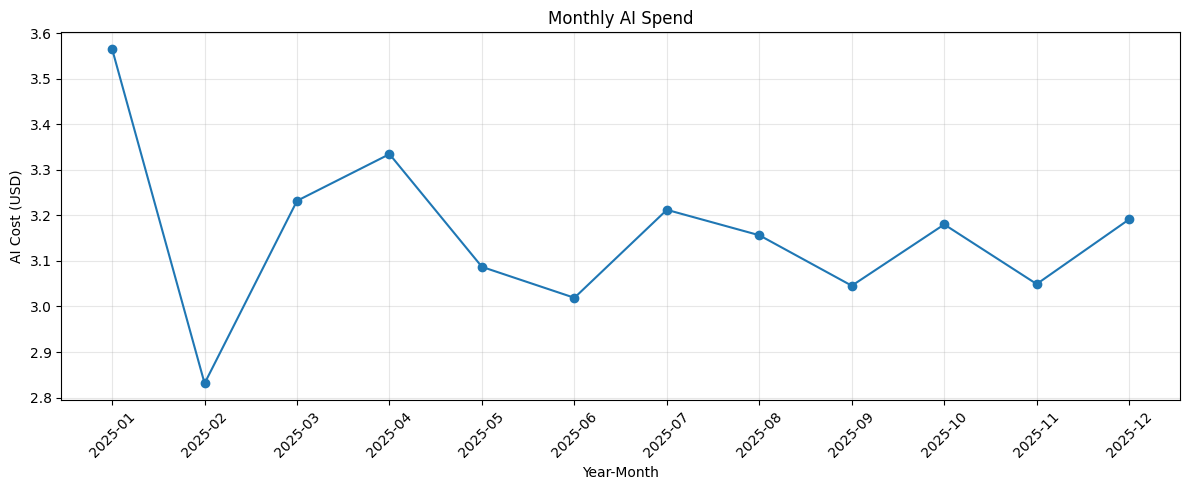

In [78]:
monthly = request_cost.dropna(subset=["request_time"]).copy()
monthly["year_month"] = monthly["request_time"].dt.to_period("M").astype(str)

monthly_summary = (
    monthly.groupby("year_month", as_index=False)
    .agg(
        requests=("request_id", "nunique"),
        input_tokens=("input_tokens", "sum"),
        output_tokens=("output_tokens", "sum"),
        ai_cost_usd=("ai_cost_usd", "sum")
    )
    .sort_values("year_month")
)
monthly_summary["total_tokens"] = monthly_summary["input_tokens"] + monthly_summary["output_tokens"]
monthly_summary["cost_mom_change_pct"] = monthly_summary["ai_cost_usd"].pct_change() * 100
display(monthly_summary)

plt.figure(figsize=(12, 5))
plt.plot(monthly_summary["year_month"], monthly_summary["ai_cost_usd"], marker="o")
plt.title("Monthly AI Spend")
plt.xlabel("Year-Month")
plt.ylabel("AI Cost (USD)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 12. Department and model analysis

In [79]:

# ============================================================
# AETHERAI - DEPARTMENT & MODEL LEVEL ANALYSIS
# ============================================================

import pandas as pd

# ------------------------------------------------------------
# 1. ATTACH DEPARTMENT INFORMATION TO EMPLOYEES
# ------------------------------------------------------------

employee_dept = tables["employees"][
    ["employee_id", "department_id"]
].merge(
    tables["departments"][
        ["department_id", "department_name"]
    ],
    on="department_id",
    how="left",
    validate="many_to_one"
)

# Validate employee department mapping
if employee_dept["department_name"].isna().any():
    raise ValueError("ERROR: Employee department mapping is missing.")

# ------------------------------------------------------------
# 2. ATTACH DEPARTMENT INFORMATION TO REQUEST DATA
# ------------------------------------------------------------

dept_cost = request_cost.merge(
    employee_dept[
        ["employee_id", "department_id", "department_name"]
    ],
    on="employee_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

# Validate request mapping
if (dept_cost["_merge"] != "both").any():
    raise ValueError("ERROR: Some requests have no employee department mapping.")

dept_cost = dept_cost.drop(columns=["_merge"])

# Ensure merge did not increase request rows
if len(dept_cost) != len(request_cost):
    raise ValueError("ERROR: Request row count changed after department merge.")

# ------------------------------------------------------------
# 3. DEPARTMENT-LEVEL SUMMARY
# ------------------------------------------------------------

department_summary = (
    dept_cost.groupby(
        ["department_id", "department_name"],
        dropna=False,
        as_index=False
    )
    .agg(
        requests=("request_id", "nunique"),
        input_tokens=("input_tokens", "sum"),
        output_tokens=("output_tokens", "sum"),
        ai_cost_usd=("ai_cost_usd", "sum"),
        average_latency_ms=("latency_ms", "mean")
    )
)

# Calculate total tokens correctly
department_summary["total_tokens"] = (
    department_summary["input_tokens"]
    + department_summary["output_tokens"]
)

# Average cost per request
department_summary["average_cost_per_request_usd"] = (
    department_summary["ai_cost_usd"]
    / department_summary["requests"].replace(0, pd.NA)
)

# Department cost contribution
total_ai_cost = request_cost["ai_cost_usd"].sum()

department_summary["cost_share_pct"] = (
    department_summary["ai_cost_usd"] / total_ai_cost * 100
    if total_ai_cost > 0 else 0
)

# Sort by highest cost
department_summary = department_summary.sort_values(
    "ai_cost_usd",
    ascending=False
)

print("DEPARTMENT-LEVEL SUMMARY")
display(department_summary)

# ------------------------------------------------------------
# 4. MODEL-LEVEL SUMMARY
# ------------------------------------------------------------

model_summary = (
    request_cost.groupby(
        ["provider", "model_name", "model_tier"],
        dropna=False,
        as_index=False
    )
    .agg(
        requests=("request_id", "nunique"),
        input_tokens=("input_tokens", "sum"),
        output_tokens=("output_tokens", "sum"),
        ai_cost_usd=("ai_cost_usd", "sum"),
        average_latency_ms=("latency_ms", "mean")
    )
)

# Calculate total tokens
model_summary["total_tokens"] = (
    model_summary["input_tokens"]
    + model_summary["output_tokens"]
)

# Average cost per request
model_summary["average_cost_per_request_usd"] = (
    model_summary["ai_cost_usd"]
    / model_summary["requests"].replace(0, pd.NA)
)

# Model cost contribution
model_summary["cost_share_pct"] = (
    model_summary["ai_cost_usd"] / total_ai_cost * 100
    if total_ai_cost > 0 else 0
)

# Sort by highest cost
model_summary = model_summary.sort_values(
    "ai_cost_usd",
    ascending=False
)

print("\nMODEL-LEVEL SUMMARY")
display(model_summary)

# ------------------------------------------------------------
# 5. FINAL DATA RECONCILIATION
# ------------------------------------------------------------

request_count = request_cost["request_id"].nunique()

request_input_tokens = request_cost["input_tokens"].sum()
request_output_tokens = request_cost["output_tokens"].sum()
request_total_tokens = request_input_tokens + request_output_tokens
request_total_cost = request_cost["ai_cost_usd"].sum()

print("\n========== FINAL VALIDATION ==========")

print("\nREQUEST LEVEL")
print("Unique Requests:", request_count)
print("Input Tokens:", request_input_tokens)
print("Output Tokens:", request_output_tokens)
print("Total Tokens:", request_total_tokens)
print("Total AI Cost USD:", round(request_total_cost, 6))

print("\nDEPARTMENT LEVEL")
print("Requests:", department_summary["requests"].sum())
print("Input Tokens:", department_summary["input_tokens"].sum())
print("Output Tokens:", department_summary["output_tokens"].sum())
print("Total Tokens:", department_summary["total_tokens"].sum())
print("Total AI Cost USD:", round(department_summary["ai_cost_usd"].sum(), 6))

print("\nMODEL LEVEL")
print("Requests:", model_summary["requests"].sum())
print("Input Tokens:", model_summary["input_tokens"].sum())
print("Output Tokens:", model_summary["output_tokens"].sum())
print("Total Tokens:", model_summary["total_tokens"].sum())
print("Total AI Cost USD:", round(model_summary["ai_cost_usd"].sum(), 6))

# ------------------------------------------------------------
# 6. AUTOMATED VALIDATION CHECKS
# ------------------------------------------------------------

assert len(request_cost) == request_count, \
    "Duplicate request IDs found in request_cost."

assert department_summary["requests"].sum() == request_count, \
    "Department request count does not match request-level data."

assert model_summary["requests"].sum() == request_count, \
    "Model request count does not match request-level data."

assert department_summary["total_tokens"].sum() == request_total_tokens, \
    "Department token totals do not match request-level data."

assert model_summary["total_tokens"].sum() == request_total_tokens, \
    "Model token totals do not match request-level data."

assert abs(
    department_summary["ai_cost_usd"].sum() - request_total_cost
) < 0.000001, "Department AI cost does not match request-level cost."

assert abs(
    model_summary["ai_cost_usd"].sum() - request_total_cost
) < 0.000001, "Model AI cost does not match request-level cost."



DEPARTMENT-LEVEL SUMMARY


,department_id,department_name,requests,input_tokens,output_tokens,ai_cost_usd,average_latency_ms,total_tokens,average_cost_per_request_usd,cost_share_pct
0,1,Customer Support,3395,5953549,2582497,10.6477,"1,550.2062",8536046,0.0031,28.0927
1,2,Engineering,2831,5107081,2248907,9.0924,"1,552.8131",7355988,0.0032,23.9893
3,4,Sales,2304,4140531,1751775,7.4605,"1,569.8663",5892306,0.0032,19.6836
2,3,Marketing,2302,3985047,1737424,7.0887,"1,541.1560",5722471,0.0031,18.7027
4,5,Operations,1168,2049248,894795,3.6127,"1,561.7423",2944043,0.0031,9.5317



MODEL-LEVEL SUMMARY


,provider,model_name,model_tier,requests,input_tokens,output_tokens,ai_cost_usd,average_latency_ms,total_tokens,average_cost_per_request_usd,cost_share_pct
1,Aether Cloud,Aether-Pro,Premium,3126,5513490,2392637,30.1681,"1,567.7412",7906127,0.0097,79.5948
0,Aether Cloud,Aether-Flash,Low Cost,7117,12541699,5446330,6.8654,"1,551.1836",17988029,0.0010,18.1135
2,Open Model Hub,OpenLite,Low Cost,1757,3180267,1376431,0.8686,"1,540.8418",4556698,0.0005,2.2917



========== FINAL VALIDATION ==========

REQUEST LEVEL
Unique Requests: 12000
Input Tokens: 21235456
Output Tokens: 9215398
Total Tokens: 30450854
Total AI Cost USD: 37.902079

DEPARTMENT LEVEL
Requests: 12000
Input Tokens: 21235456
Output Tokens: 9215398
Total Tokens: 30450854
Total AI Cost USD: 37.902079

MODEL LEVEL
Requests: 12000
Input Tokens: 21235456
Output Tokens: 9215398
Total Tokens: 30450854
Total AI Cost USD: 37.902079


## 13. Request status and latency

In [80]:
status_summary = (
    requests.assign(status_clean=status)
    .groupby("status_clean")
    .agg(requests=("request_id", "nunique"),
         average_latency_ms=("latency_ms", "mean"))
    .reset_index()
)
status_summary["share_of_requests_pct"] = (
    status_summary["requests"] / total_requests * 100 if total_requests else np.nan
)
display(status_summary)

latency_by_model = (
    request_cost.groupby("model_name", dropna=False)
    .agg(requests=("request_id", "nunique"),
         average_latency_ms=("latency_ms", "mean"),
         ai_cost_usd=("ai_cost_usd", "sum"))
    .reset_index()
    .sort_values("average_latency_ms", ascending=False)
)
display(latency_by_model)

,status_clean,requests,average_latency_ms,share_of_requests_pct
0,error,348,"1,587.4483",2.9000
1,success,11476,"1,553.4396",95.6333
2,timeout,176,"1,523.2216",1.4667


,model_name,requests,average_latency_ms,ai_cost_usd
1,Aether-Pro,3126,"1,567.7412",30.1681
0,Aether-Flash,7117,"1,551.1836",6.8654
2,OpenLite,1757,"1,540.8418",0.8686


## 14. Task outcomes, time saved and estimated labor value
The task outcome table may have a different grain or duplicate request IDs. Inspect its uniqueness before joining it to request-level data.

In [81]:
outcomes = tables["task_outcomes"].copy()
print("Task outcome rows:", len(outcomes))
print("Unique outcome request IDs:", outcomes["request_id"].nunique())
print("Duplicate outcome request IDs:", outcomes["request_id"].duplicated().sum())

if outcomes["request_id"].duplicated().any():
    print("WARNING: Outcomes are not one row per request. Do not merge directly to request_cost until duplicates are understood.")

outcomes["estimated_labor_value_usd"] = (
    outcomes["time_saved_minutes"] * outcomes["hourly_labor_cost_usd"] / 60
)

total_time_saved_hours = outcomes["time_saved_minutes"].sum() / 60
estimated_labor_value = outcomes["estimated_labor_value_usd"].sum()

# Task success parsing accommodates Boolean values and common text values.
success_text = outcomes["task_successful"].astype(str).str.strip().str.lower()
successful_task_mask = success_text.isin(["true", "1", "yes", "successful", "success"])
successful_tasks = int(successful_task_mask.sum())

print(f"Successful tasks: {successful_tasks:,}")
print(f"Time saved (hours): {total_time_saved_hours:,.2f}")
print(f"Estimated labor value (USD): ${estimated_labor_value:,.2f}")
print("This is an estimate based on recorded time and assumed hourly labor rates.")

Task outcome rows: 12000
Unique outcome request IDs: 12000
Duplicate outcome request IDs: 0
Successful tasks: 10,302
Time saved (hours): 2,734.55
Estimated labor value (USD): $90,326.00
This is an estimate based on recorded time and assumed hourly labor rates.


## 15. Estimated ROI — calculate and interpret carefully

In [82]:
if pd.notna(total_ai_cost) and total_ai_cost > 0:
    estimated_roi_ratio = (estimated_labor_value - total_ai_cost) / total_ai_cost
    estimated_roi_pct = estimated_roi_ratio * 100
else:
    estimated_roi_ratio = np.nan
    estimated_roi_pct = np.nan

print(f"AI cost: ${total_ai_cost:,.4f}")
print(f"Estimated labor value: ${estimated_labor_value:,.2f}")
print(f"Estimated ROI: {estimated_roi_pct:,.2f}%")

print("\nInterpretation warning:")
print("- This is a modeled estimate, not audited or realized cash savings.")
print("- Verify time_saved_minutes and hourly_labor_cost_usd assumptions.")
print("- Confirm labor value and AI cost cover the same dates and comparable request population.")
print("- Do not join duplicated task outcomes to requests without resolving the grain.")

AI cost: $37.9021
Estimated labor value: $90,326.00
Estimated ROI: 238,214.11%

Interpretation warning:
- This is a modeled estimate, not audited or realized cash savings.
- Verify time_saved_minutes and hourly_labor_cost_usd assumptions.
- Confirm labor value and AI cost cover the same dates and comparable request population.
- Do not join duplicated task outcomes to requests without resolving the grain.


## 16. Budget analysis — compare matching department-month grain
Budget rows are at department-month grain. Avoid expanding budget rows across individual requests and summing the repeated values.

In [83]:

# 16. Budget analysis — compare matching department-month grain

# Copy source tables
budgets = tables["department_budgets"].copy()
employees = tables["employees"].copy()
departments = tables["departments"].copy()

print("Budget columns:", budgets.columns.tolist())
print("Department columns:", departments.columns.tolist())

# 1. Add department_id to dept_cost through employees
if "department_id" not in dept_cost.columns:
    dept_cost = dept_cost.merge(
        employees[["employee_id", "department_id"]],
        on="employee_id",
        how="left",
        validate="many_to_one"
    )

# 2. Add department_name through departments
if "department_name" not in dept_cost.columns:
    dept_cost = dept_cost.merge(
        departments[["department_id", "department_name"]],
        on="department_id",
        how="left",
        validate="many_to_one"
    )

# 3. Convert dates
dept_cost["request_time"] = pd.to_datetime(
    dept_cost["request_time"], errors="coerce"
)

budgets["budget_month"] = pd.to_datetime(
    budgets["budget_month"], errors="coerce"
)

# 4. Create Year-Month
dept_cost["year_month"] = (
    dept_cost["request_time"].dt.to_period("M").astype(str)
)

budgets["year_month"] = (
    budgets["budget_month"].dt.to_period("M").astype(str)
)

# 5. Aggregate actual spend at department-month grain
monthly_dept_spend = (
    dept_cost.dropna(subset=["request_time"])
    .groupby(
        ["department_id", "department_name", "year_month"],
        as_index=False,
        dropna=False
    )
    .agg(actual_spend_usd=("ai_cost_usd", "sum"))
)

# 6. Aggregate budget at department-month grain
budget_check = (
    budgets.dropna(subset=["budget_month"])
    .groupby(
        ["department_id", "year_month"],
        as_index=False
    )
    .agg(budget_amount_usd=("budget_amount_usd", "sum"))
)

# 7. Merge actual spend and budget
budget_analysis = monthly_dept_spend.merge(
    budget_check,
    on=["department_id", "year_month"],
    how="outer",
    validate="one_to_one"
)

# 8. Add department names for budget-only records
budget_analysis = budget_analysis.merge(
    departments[["department_id", "department_name"]],
    on="department_id",
    how="left",
    validate="many_to_one",
    suffixes=("", "_master")
)

budget_analysis["department_name"] = (
    budget_analysis["department_name"]
    .fillna(budget_analysis["department_name_master"])
)

budget_analysis.drop(
    columns=["department_name_master"],
    inplace=True
)

# 9. Calculate budget KPIs
budget_analysis["budget_variance_usd"] = (
    budget_analysis["actual_spend_usd"]
    - budget_analysis["budget_amount_usd"]
)

budget_analysis["budget_utilization_pct"] = (
    budget_analysis["actual_spend_usd"]
    .div(budget_analysis["budget_amount_usd"].replace(0, pd.NA))
    * 100
)

# 10. Display final report
budget_analysis = budget_analysis.sort_values(
    ["year_month", "department_name"]
)

display(budget_analysis)


Budget columns: ['department_id', 'budget_month', 'budget_amount_usd']
Department columns: ['department_id', 'department_name', 'monthly_budget_usd']


,department_id,department_name,year_month,actual_spend_usd,budget_amount_usd,budget_variance_usd,budget_utilization_pct
0,1,Customer Support,2025-01,0.9460,1800,"-1,799.0540",0.0526
12,2,Engineering,2025-01,1.1096,3200,"-3,198.8904",0.0347
24,3,Marketing,2025-01,0.6441,1500,"-1,499.3559",0.0429
48,5,Operations,2025-01,0.3453,1300,"-1,299.6547",0.0266
36,4,Sales,2025-01,0.5198,1700,"-1,699.4802",0.0306
1,1,Customer Support,2025-02,0.8754,1800,"-1,799.1246",0.0486
13,2,Engineering,2025-02,0.5413,3200,"-3,199.4587",0.0169
25,3,Marketing,2025-02,0.5575,1500,"-1,499.4425",0.0372
49,5,Operations,2025-02,0.2693,1300,"-1,299.7307",0.0207
37,4,Sales,2025-02,0.5877,1700,"-1,699.4123",0.0346


## 17. KPI reconciliation against the Power BI PDF

The latest PDF showed:
- AI cost: `$37.90`
- Requests: `12K`
- Tokens: `30M`
- Request success rate: `95.63%`
- Estimated labor value: `$90.33K`
- Estimated ROI: `238.21K%`
- Monthly budget: `$114.00K`
- Budget utilization: `3.32%`

**Important correction:** if actual spend is `$37.90` and the selected budget is `$114,000`, utilization is:

`37.90 / 114000 = 0.00033246` as a ratio, or **0.033246%** when formatted as a percentage.

A displayed **3.32%** is approximately 100 times too high for those two values. Confirm that the card's actual filter context and budget value are exactly those values. The measure should be a ratio without `* 100`, formatted as Percentage in Power BI.

The 238.21K% ROI is mathematically consistent with roughly `$90.33K` estimated labor value versus `$37.90` AI cost, but it is a warning that the assumptions/populations need validation—not a number to cosmetically reduce.

In [84]:
budget_ratio_from_pdf = 37.90 / 114000
print(f"Budget utilization ratio: {budget_ratio_from_pdf:.8f}")
print(f"Budget utilization as percentage: {budget_ratio_from_pdf*100:.5f}%")
print(f"ROI from rounded PDF values: {((90330 - 37.90) / 37.90) * 100:,.2f}%")
print("PDF values are rounded; use full-precision underlying measures for final reconciliation.")

Budget utilization ratio: 0.00033246
Budget utilization as percentage: 0.03325%
ROI from rounded PDF values: 238,237.73%
PDF values are rounded; use full-precision underlying measures for final reconciliation.


## 18. Export analysis outputs

In [85]:
output_dir = Path("/content/aetherai_outputs")
output_dir.mkdir(exist_ok=True)

monthly_summary.to_csv(output_dir / "monthly_summary.csv", index=False)
department_summary.to_csv(output_dir / "department_summary.csv", index=False)
model_summary.to_csv(output_dir / "model_summary.csv", index=False)
status_summary.to_csv(output_dir / "request_status_summary.csv", index=False)
request_cost.to_csv(output_dir / "request_level_cost_analysis.csv", index=False)

print("Exported files:")
for p in sorted(output_dir.glob("*.csv")):
    print(p.name, f"({p.stat().st_size:,} bytes)")

Exported files:
department_summary.csv (703 bytes)
model_summary.csv (558 bytes)
monthly_summary.csv (855 bytes)
request_level_cost_analysis.csv (1,837,087 bytes)
request_status_summary.csv (210 bytes)


## 19. Download the outputs

In [86]:
import shutil
zip_path = shutil.make_archive("/content/AetherAI_Analysis_Outputs", "zip", output_dir)
files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 20. Final analyst checklist

- [ ] All seven CSVs loaded.
- [ ] Row counts and date range checked.
- [ ] Duplicate keys and missing values investigated.
- [ ] Token and model rates validated.
- [ ] Request-level cost calculated without row multiplication.
- [ ] Monthly and department costs reviewed.
- [ ] Task outcome grain checked before combining with requests.
- [ ] Estimated labor value assumptions reviewed.
- [ ] ROI interpreted as an estimate, not realized savings.
- [ ] Budget compared at department-month grain.
- [ ] Python results reconciled with PostgreSQL and Power BI.
- [ ] Findings and limitations documented.

**Do not publish until key metrics reconcile across PostgreSQL, Python and Power BI.**